# How guessable is each item?

Prolific participants guessed the answers to the OneStop and RACE questions. An item guessed right far
more often than one in four gives its answer away without the text; one guessed right far less often has a
wrong answer that draws guessers to it. Here, for every item, how many of its guessers got it right.

Two datasets, kept apart because the question and answer texts changed between them:

* **`guess.tsv`** -- each participant guessed two OneStop and two RACE questions. About three guesses per item.
* **The pilot batches** -- an earlier version of the OneStop questions. Each participant worked through one
  article, a question per paragraph, answering each question once before the paragraph was shown -- the guess
  used here -- and once after reading it. About sixteen guesses per item.

**An item is a question at one difficulty level**, as both files define it. OneStop shows the same question
and answers at both levels (Ele, Adv), so a OneStop question appears as two items with identical text.

**Reading the histograms.** Bars are items. Black dots are what the bars would be if every item were guessed
right at the panel's overall rate, each with its own number of guesses; grey diamonds, if every guess were
one in four. Bars above the black dots at the two ends are items that really are easier or harder to guess
than the rest -- more than the luck of a few guesses would put there.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from src.explorations.guessability import data as D
from src.explorations.guessability import plots as P

SAVE = True   # writes the figures and their tables to reports/explorations/guessability/
N_SHOW = 15   # items listed at each end
BIN_WIDTH = {"guess": None, "pilot": 0.1}   # None: a bar per share; three guesses give only four shares
pd.set_option("display.max_colwidth", 90)

## 1. The two datasets
*`data.load`, `data.summary_table`*

Practice questions are left out. Each loader checks that answer `0` is the correct one: `guess.tsv` against
the running score it records, the pilot by the answers given after reading the paragraph.

In [2]:
guesses = {ds: D.load(ds) for ds in D.DATASETS}
items = {ds: D.item_table(g) for ds, g in guesses.items()}
for ds, g in guesses.items():
    print(D.DATASETS[ds])
    display(D.summary_table(g).round(3))

guess: 6 practice rows left out, 3880 guesses kept
pilot: 6086 practice rows left out, 16263 guesses kept
pilot: after reading the paragraph, 70% right (the guess: 38%)
Prolific guessing data (guess.tsv)


,source,difficulty,guesses,participants,share_correct,items
0,Onestop,Adv,970,970,0.307,324
1,Onestop,Ele,970,970,0.331,324
2,RACE,High,970,970,0.378,324
3,RACE,Middle,970,970,0.428,324


Pilot batches, answered before reading the paragraph


,source,difficulty,guesses,participants,share_correct,items
0,Onestop,Adv,8136,3022,0.377,486
1,Onestop,Ele,8127,3022,0.376,486


## 2. `guess.tsv`: how often each item was guessed right
*`data.histogram_table`, `plots.plot_histogram`*

One panel per source. With three guesses, an item scores 0, 1/3, 2/3 or 3/3 (1/2 for the few items with
two).

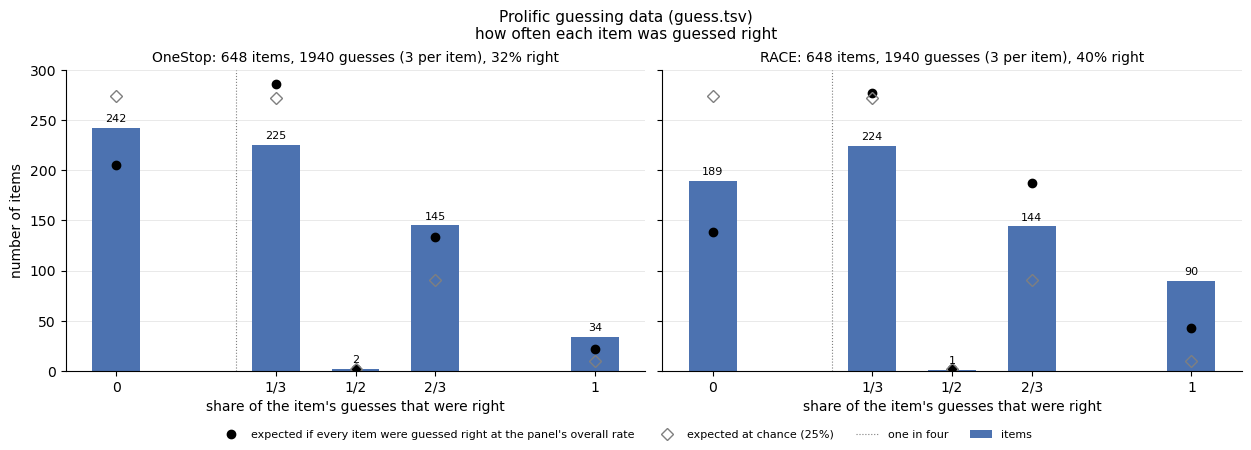

,source,bin_low,bin_high,bin,rate,items_observed,items_expected_same_rate,items_expected_chance
0,Onestop,0.0,0.0,0,0.3,242.0,205.2,273.9
1,Onestop,0.3,0.3,1/3,0.3,225.0,285.8,271.7
2,Onestop,0.5,0.5,1/2,0.3,2.0,1.7,1.5
3,Onestop,0.7,0.7,2/3,0.3,145.0,133.9,90.6
4,Onestop,1.0,1.0,1,0.3,34.0,21.3,10.3
5,RACE,0.0,0.0,0,0.4,189.0,138.4,273.9
6,RACE,0.3,0.3,1/3,0.4,224.0,277.5,271.7
7,RACE,0.5,0.5,1/2,0.4,1.0,1.9,1.5
8,RACE,0.7,0.7,2/3,0.4,144.0,187.4,90.6
9,RACE,1.0,1.0,1,0.4,90.0,42.8,10.3


In [3]:
hist = {ds: D.histogram_table(items[ds], bin_width=BIN_WIDTH[ds]) for ds in D.DATASETS}
P.plot_histogram(items["guess"], hist["guess"], "guess", save=SAVE)
plt.show()
display(hist["guess"].round(1))

## 3. `guess.tsv`: the most and least guessed items
*`data.extremes`*

With three guesses, both ends are ties: every item all its guessers got right, and every item none did. At
the bottom, items whose guessers all chose the same wrong answer come first. The counts show how many items
share each end.

In [4]:
SHOW = {
    "guess": ["item_id", "source", "difficulty", "n_guesses", "n_correct", "chose_A", "chose_B", "chose_C", "chose_D",
              "question", "correct_answer"],
    "pilot": ["article", "difficulty", "n_guesses", "n_correct", "share_correct", "chose_A", "chose_B", "chose_C",
              "chose_D", "question", "correct_answer"],
}

def show_extremes(ds):
    it = items[ds]
    print(f"all guessers right: {int((it['share_correct'] == 1).sum())} items; "
          f"none right: {int((it['share_correct'] == 0).sum())} items, of {len(it)}")
    ex = D.extremes(it, N_SHOW)
    print("Most often guessed right")
    display(ex["most"][SHOW[ds]].round(3))
    print("Least often guessed right")
    display(ex["least"][SHOW[ds]].round(3))

show_extremes("guess")

all guessers right: 124 items; none right: 431 items, of 1296
Most often guessed right


,item_id,source,difficulty,n_guesses,n_correct,chose_A,chose_B,chose_C,chose_D,question,correct_answer
0,os10_3_3_Ele,Onestop,Ele,3,3,3,0,0,0,Who has said islands will stop getting their current tax breaks?,The government
1,os10_5_3_Adv,Onestop,Adv,3,3,3,0,0,0,Why did people consider the islands as remote and obscure?,The only way to get there was by slow and unreliable ferries
2,os11_4_3_Ele,Onestop,Ele,3,3,3,0,0,0,What does Laura find satisfying when returning to some of the stores she visited while...,Seeing that her mystery shopping had an impact on the service
3,os12_2_3_Adv,Onestop,Adv,3,3,3,0,0,0,How are mud and snow useful for the scientists?,They allow the scientists to see wolf tracks better
4,os12_6_2_Adv,Onestop,Adv,3,3,3,0,0,0,Why are wolves not a big tourist attraction?,Wolves don't want to be near humans
5,os12_6_3_Ele,Onestop,Ele,3,3,3,0,0,0,Who is Jan Szyszko?,A minister in the new Polish government
6,os17_5_3_Adv,Onestop,Adv,3,3,3,0,0,0,"How have things changed for the wealthy since the 2008 financial crisis, according to ...",The gap between them and those without money has increased
7,os17_5_3_Ele,Onestop,Ele,3,3,3,0,0,0,"How have things changed for the wealthy since the 2008 financial crisis, according to ...",The gap between them and those without money has increased
8,os17_6_2_Ele,Onestop,Ele,3,3,3,0,0,0,What does Cockrell say is a common mistake that his wealthy clients make?,They define themselves by their money
9,os17_6_3_Ele,Onestop,Ele,3,3,3,0,0,0,What does Cockrell say is true if someone is part of the 1%?,"Even if they don't have problems with money, they may grapple with other issues"


Least often guessed right


,item_id,source,difficulty,n_guesses,n_correct,chose_A,chose_B,chose_C,chose_D,question,correct_answer
0,os10_2_1_Adv,Onestop,Adv,3,0,0,0,0,3,How has the closure of Greek banks affected the local residents of the island?,They have to make long trips to another island to get money
1,os10_2_2_Adv,Onestop,Adv,3,0,0,0,0,3,Why do Greek visitors no longer come to the island?,They do not have enough physical money
2,os10_7_2_Adv,Onestop,Adv,3,0,0,0,0,3,What will Kakali do if Agios Efstratios has to pay the proposed tax increase?,Visit the government with kids from Agios Efstratios
3,os11_5_2_Adv,Onestop,Adv,3,0,0,3,0,0,What is the typical amount Marketforce pays mystery shoppers for one store visit?,A few pounds
4,os11_6_1_Ele,Onestop,Ele,3,0,0,0,0,3,Who does Hanna visit as part of her mystery shopping job?,Expensive restaurants and hotels
5,os11_6_3_Ele,Onestop,Ele,3,0,0,0,3,0,What is one thing Hannah must do when eating at a restaurant as a mystery diner?,Commit specifics of the experience to memory
6,os12_1_2_Ele,Onestop,Ele,3,0,0,0,0,3,"Why do scientists from Britain, Germany and the Netherlands come to Poland?",To learn how wolves were saved in Poland
7,os12_3_1_Adv,Onestop,Adv,3,0,0,3,0,0,What is a result of the predatory habits of wolves?,It allows birds to have tall trees to nest in
8,os12_3_3_Adv,Onestop,Adv,3,0,0,3,0,0,Where was wolf-hunting banned in 1995?,The western Carpathian mountains
9,os12_6_1_Ele,Onestop,Ele,3,0,0,0,0,3,Why is it hard to support wolves in Poland's new government?,Wolf hunters have a large influence in the government


## 4. The pilot: how often each item was guessed right
*`data.histogram_table`, `plots.plot_histogram`*

About sixteen guesses per item, so shares are pooled into bins a tenth wide, and the expected counts are
binned the same way.

**These guesses are not all made blind.** Every pilot session is one article, a question per paragraph, so from
the second question on the participant has already read earlier paragraphs of the same article. Section 6
shows what that does to the share right.

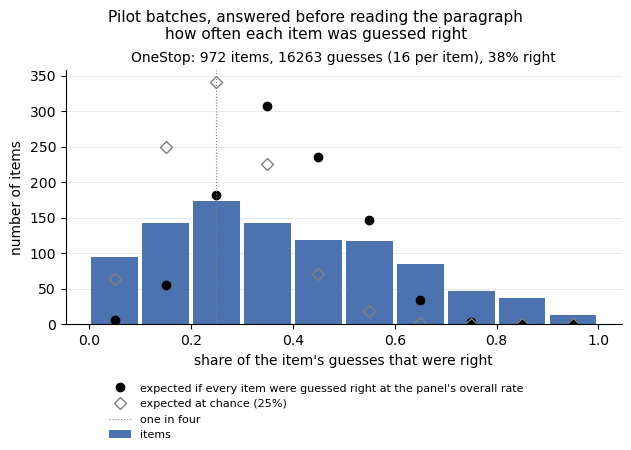

,source,bin_low,bin_high,bin,rate,items_observed,items_expected_same_rate,items_expected_chance
0,Onestop,0.0,0.1,0.00-0.10,0.4,94.0,6.0,63.7
1,Onestop,0.1,0.2,0.10-0.20,0.4,143.0,55.1,249.4
2,Onestop,0.2,0.3,0.20-0.30,0.4,174.0,182.6,341.2
3,Onestop,0.3,0.4,0.30-0.40,0.4,143.0,307.4,225.5
4,Onestop,0.4,0.5,0.40-0.50,0.4,119.0,235.3,71.1
5,Onestop,0.5,0.6,0.50-0.60,0.4,117.0,146.9,19.2
6,Onestop,0.6,0.7,0.60-0.70,0.4,85.0,34.4,1.7
7,Onestop,0.7,0.8,0.70-0.80,0.4,47.0,3.7,0.1
8,Onestop,0.8,0.9,0.80-0.90,0.4,37.0,0.4,0.0
9,Onestop,0.9,1.0,0.90-1.00,0.4,13.0,0.0,0.0


In [5]:
## 


P.plot_histogram(items["pilot"], hist["pilot"], "pilot", save=SAVE)
plt.show()
display(hist["pilot"].round(1))

## 5. The pilot: the most and least guessed items
*`data.extremes`*

Ties are broken by more guesses, and at the bottom then by how strongly the guessers agreed on one wrong
answer. `chose_A` is the correct answer.

In [6]:
show_extremes("pilot")

all guessers right: 0 items; none right: 31 items, of 972
Most often guessed right


,article,difficulty,n_guesses,n_correct,share_correct,chose_A,chose_B,chose_C,chose_D,question,correct_answer
0,Hundreds Hurt after Meteorite Falls to Earth,Ele,22,21,0.955,21,0,0,1,What is true of most of the people who came into the clinic where Bets works?,They were injured by glass
1,Japan Calls Time on Long Hours Work Culture,Adv,19,18,0.947,18,0,0,1,What are Japanese workers likely to think about taking a two-week summer holiday?,That it is unnecessarily long
2,Bright Future for Astrotourism,Adv,17,16,0.941,16,0,1,0,Why do tourists go to Northumberland in autumn and winter?,Because the sky is the darkest then
3,Japan Calls Time on Long Hours Work Culture,Ele,17,16,0.941,16,1,0,0,Why is Japan's population declining?,Work culture makes it difficult for couples to start families
4,Google Introduces its Driverless Car,Ele,16,15,0.938,15,0,1,0,What will Google do now?,Test pilot the cars
5,Why You Should Start Work at 10AM,Adv,16,15,0.938,15,1,0,0,"According to Kelley, how would staggered starting times benefit workplaces?",Work would be done more effectively
6,Why You Should Start Work at 10AM,Adv,16,15,0.938,15,1,0,0,Why does Kelley say that going to bed earlier is not the solution to waking up earlier?,"Light, rather than the time people go to bed, controls people's natural sleep rhythms"
7,Why You Should Start Work at 10AM,Ele,16,15,0.938,15,1,0,0,"According to Kelley, what creates difficulties for parents in the morning?",Waking up their teenage kids
8,Love Hormone Helps Autistic Children Bond with Others,Ele,15,14,0.933,14,0,0,1,What were the two different groups in the experiment?,One group was given oxytocin; the other was given placebo
9,The Greek Island Where Time Is Running Out,Ele,15,14,0.933,14,1,0,0,"What is the upcoming ""bigger crisis""?",Islands will have to pay more taxes


Least often guessed right


,article,difficulty,n_guesses,n_correct,share_correct,chose_A,chose_B,chose_C,chose_D,question,correct_answer
0,Bright Future for Astrotourism,Adv,23,0,0.0,0,3,6,14,Who is quoted as saying that hotels benefit from the park's new Dark Sky status?,An employee of a car-hire company
1,Morocco Poised to Become a Solar Superpower,Adv,21,0,0.0,0,2,9,10,What will happen once the four plants are finished?,They will be as large as the capital
2,Hundreds Hurt after Meteorite Falls to Earth,Adv,20,0,0.0,0,3,1,16,"Who was in shock, according to Bets?",College students
3,Man Falls Just Short in Patriot Game to be 100% French,Adv,19,0,0.0,0,2,12,5,What did Carle's guests do?,Listened to music while standing
4,Bright Future for Astrotourism,Ele,17,0,0.0,0,1,6,10,Who is quoted as saying that hotels benefit from the park's new Dark Sky status?,An employee of a car-hire company
5,Nepal's Tiger Population on the Rise,Adv,17,0,0.0,0,2,10,5,When will India finish its tiger survey?,In 2013
6,Swarthy Blue-Eyed Caveman Revealed,Adv,17,0,0.0,0,2,5,10,Where did the Mesolithic man live?,Spain
7,Inky the Octopus Escapes from Aquarium,Adv,16,0,0.0,0,1,2,13,Why does Inky's escape make sense to Yarrell?,Inky has been known to surprise people
8,Google Introduces its Driverless Car,Ele,16,0,0.0,0,12,1,3,Who is planning on implementing driver controls in self-driving cars?,"Volvo, Ford and Mercedes"
9,Love Hormone Helps Autistic Children Bond with Others,Adv,16,0,0.0,0,2,2,12,"According to Frith, what would be the crucial piece of evidence needed for showing oxy...",The existence of behavioral effects


## 6. The pilot: guesses later in the session
*`data.position_table`*

The share of guesses right by the question's place in the session. The first question is the only one
guessed before reading anything of the article.

In [7]:
display(D.position_table(guesses["pilot"]).round(3))

,position,guesses,share_correct
0,1,3023,0.332
1,2,3021,0.383
2,3,3019,0.406
3,4,3011,0.400
4,5,2317,0.364
5,6,1372,0.386
6,7,500,0.316
